# 03 · Backtest honesto

Un **backtest** es simular qué habría pasado si hubiéramos operado con una regla en el pasado. Es fácil engañarse, así que seguimos tres reglas:

1. **Dividir en el tiempo.** Elegimos la regla mirando solo los **primeros 2/3** de los datos y la probamos en el **último 1/3**, que no miramos. Es como estudiar con unos ejercicios y rendir con otros.
2. **Pagar comisiones** en cada operación, y el **funding** mientras la posición está abierta.
3. **Probar variaciones.** Si solo funciona en un caso exacto, probablemente fue suerte.

**La regla:** si el z del funding supera un umbral, apostamos a la **baja** durante H horas (*short*). Si es menor que menos el umbral, apostamos a la **suba** (*long*).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (11, 4)

COIN = "BTC"   # cambiá a "ETH" o "SOL" para mirar otra moneda
df = pd.read_csv(f"../data/{COIN}.csv", parse_dates=["time"])
H = 8
COMISION = 0.00035  # 0,035 % por operación (verificá la tarifa vigente de Hyperliquid)
W = 168
df["z"] = (df["fundingRate"] - df["fundingRate"].rolling(W).mean()) / df["fundingRate"].rolling(W).std()
df = df.dropna(subset=["z"]).reset_index(drop=True)

## La simulación

Recorre las horas en orden. Si no hay posición abierta y el z cruza el umbral, abre una y la mantiene H horas. El resultado de cada operación es:

`resultado = dirección × retorno del precio − 2 comisiones (entrar y salir) − dirección × funding pagado`

(dirección = +1 si es long, −1 si es short; un long paga el funding cuando es positivo y un short lo cobra).

In [2]:
def backtest(d, umbral, H=H):
    ops, i = [], 0
    while i < len(d) - H:
        z = d.at[i, "z"]
        if abs(z) >= umbral:
            dir_ = -1 if z > 0 else 1
            ret = d.at[i + H, "close"] / d.at[i, "close"] - 1
            fund = d["fundingRate"].iloc[i + 1:i + H + 1].fillna(0).sum()
            ops.append({"time": d.at[i, "time"], "dir": dir_, "pnl": dir_ * ret - 2 * COMISION - dir_ * fund})
            i += H  # no abrimos otra hasta cerrar esta
        else:
            i += 1
    return pd.DataFrame(ops)


def medir(ops, nombre=""):
    if ops.empty:
        return {"nombre": nombre, "ops": 0}
    curva = ops["pnl"].cumsum()
    por_año = len(ops) / ((ops.time.max() - ops.time.min()).days / 365 + 1e-9)
    return {
        "nombre": nombre,
        "ops": len(ops),
        "ganancia total %": round(ops.pnl.sum() * 100, 2),
        "aciertos %": round((ops.pnl > 0).mean() * 100, 1),
        "sharpe": round(ops.pnl.mean() / ops.pnl.std() * np.sqrt(por_año), 2) if ops.pnl.std() > 0 else None,
        "peor caída %": round((curva - curva.cummax()).min() * 100, 2),
    }

## Paso 1: elegir el umbral **solo con el período de entrenamiento**

Probamos tres umbrales en los primeros 2/3 y nos quedamos con el mejor. El período de prueba todavía no se toca.

In [3]:
corte = int(len(df) * 2 / 3)
train, test = df.iloc[:corte].reset_index(drop=True), df.iloc[corte:].reset_index(drop=True)
print("Entrenamiento:", train.time.min().date(), "→", train.time.max().date())
print("Prueba:       ", test.time.min().date(), "→", test.time.max().date())

res = pd.DataFrame([medir(backtest(train, u), f"umbral {u}") for u in [1.5, 2.0, 2.5]])
res

Entrenamiento: 2026-04-14 → 2026-08-22
Prueba:        2026-08-22 → 2026-10-24


,nombre,ops,ganancia total %,aciertos %,sharpe,peor caída %
0,umbral 1.5,106,-11.46,43.4,-2.06,-12.69
1,umbral 2.0,61,-2.35,44.3,-0.54,-5.87
2,umbral 2.5,41,0.95,48.8,0.27,-4.70


## Paso 2: la prueba de verdad

Usamos el umbral elegido en el período de **prueba**, que nunca miramos. **Este es el resultado que cuenta.**

- Si gana en entrenamiento pero pierde en prueba: era casualidad (*sobreajuste*).
- Si gana en los dos: posible señal, pero hay que seguir probando.

{'nombre': 'PRUEBA · umbral 2.5', 'ops': 28, 'ganancia total %': np.float64(0.49), 'aciertos %': np.float64(57.1), 'sharpe': np.float64(0.28), 'peor caída %': np.float64(-2.87)}


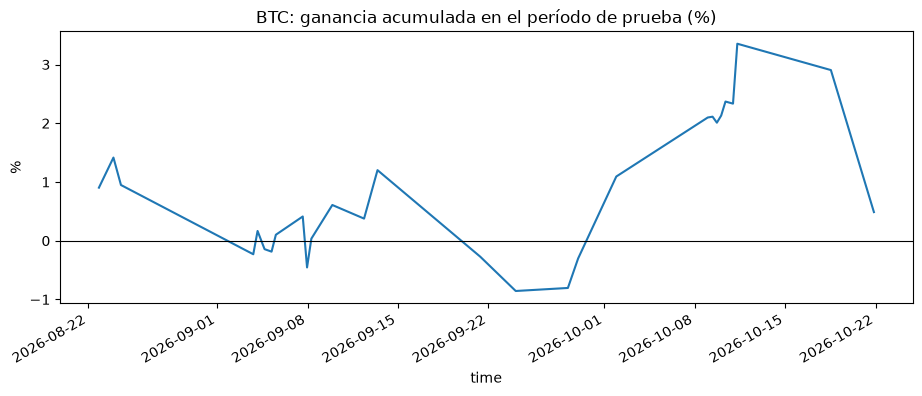

In [4]:
mejor = float(res.sort_values("ganancia total %", ascending=False).iloc[0]["nombre"].split()[-1])
ops = backtest(test, mejor)
print(medir(ops, f"PRUEBA · umbral {mejor}"))

if not ops.empty:
    (ops.set_index("time")["pnl"].cumsum() * 100).plot(title=f"{COIN}: ganancia acumulada en el período de prueba (%)")
    plt.axhline(0, color="black", lw=0.8); plt.ylabel("%"); plt.show()

## Paso 3: robustez

¿Funciona también en otras monedas y con otros horizontes? Si la ganancia aparece solo en una combinación exacta, lo más probable es que sea suerte.

In [5]:
filas = []
for coin in ["BTC", "ETH", "SOL"]:
    d = pd.read_csv(f"../data/{coin}.csv", parse_dates=["time"])
    d["z"] = (d["fundingRate"] - d["fundingRate"].rolling(W).mean()) / d["fundingRate"].rolling(W).std()
    d = d.dropna(subset=["z"]).reset_index(drop=True)
    t = d.iloc[int(len(d) * 2 / 3):].reset_index(drop=True)
    for h in [4, 8, 24]:
        filas.append(medir(backtest(t, mejor, H=h), f"{coin} · {h} h"))
pd.DataFrame(filas)

,nombre,ops,ganancia total %,aciertos %,sharpe,peor caída %
0,BTC · 4 h,35,-3.65,34.3,-2.73,-4.63
1,BTC · 8 h,28,0.49,57.1,0.28,-2.87
2,BTC · 24 h,17,-7.69,47.1,-3.20,-7.61
3,ETH · 4 h,23,1.50,47.8,0.63,-8.19
4,ETH · 8 h,18,2.45,44.4,1.04,-6.09
5,ETH · 24 h,12,4.01,50.0,1.93,-5.27
6,SOL · 4 h,34,1.00,58.8,0.29,-3.78
7,SOL · 8 h,26,-1.85,46.2,-0.56,-10.29
8,SOL · 24 h,18,-2.93,50.0,-0.48,-8.95


## Glosario de los resultados
- **ops:** cuántas operaciones hizo.
- **ganancia total %:** la suma de todas las operaciones, ya con comisiones y funding.
- **aciertos %:** qué porcentaje de operaciones ganó.
- **sharpe:** ganancia por unidad de riesgo, llevada a un año. Arriba de 1 es bueno; arriba de 2, sospechosamente bueno (revisá que no haya un error).
- **peor caída %:** lo máximo que llegó a perder desde un pico. Mide cuánto dolor aguantás.

## Qué escribir en el README
- El resultado del **período de prueba** (no el de entrenamiento).
- La tabla de robustez.
- Las limitaciones: pocos meses, un solo tipo de mercado, comisiones aproximadas, sin deslizamiento.